[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/fxrdhan/analisis-penumpang-subway-nyc-2026/blob/main/Analisis_Penumpang_Subway_NYC_2026.ipynb)

# Analisis Data Penumpang *Subway* New York City per Jam, Januari–November 2026

**Mata kuliah Data Sains dan Analisis**

| Nama | NIM |
|---|---|
| Muhammad Raffi Ibrahim | 101032300020 |
| Zacky Yusup Hakim | 101032300183 |
| Firdaus Arif Ramadhani | 101032300131 |

*Notebook* ini terdiri atas empat tahap: pengumpulan data dari API resmi MTA, *pre-processing*, penelaahan data
(*exploratory data analysis*), dan persiapan data untuk pemodelan. Setiap kesimpulan bersandar pada keluaran sel di
atasnya atau pada sumber resmi yang ditautkan.

## 1. Pendahuluan

Metropolitan Transportation Authority (MTA) menerbitkan jumlah penumpang yang masuk ke setiap kompleks stasiun
*subway* New York City untuk setiap jam. Sebelum dipakai untuk menjawab kapan dan di mana penumpang paling banyak,
data tersebut perlu dikumpulkan, diperiksa kelengkapannya, dan dibersihkan.

Pertanyaan penelitian:

1. Apakah data yang dikumpulkan lengkap dan sama dengan data di server MTA?
2. Masalah kualitas apa yang ada pada data, dan bagaimana penanganannya?
3. Bagaimana sebaran jumlah penumpang, termasuk kuartil dan *outlier*-nya?
4. Pada jam, hari, bulan, dan stasiun mana penumpang paling banyak?
5. Bagaimana korelasi antarvariabel numerik?

Istilah yang dipakai:

- **Kompleks stasiun**: satu lokasi stasiun tempat penumpang masuk; kompleks besar seperti Times Sq-42 St dilayani
  beberapa jalur kereta.
- ***Borough***: lima wilayah kota New York City, yaitu Manhattan, Brooklyn, Queens, Bronx, dan Staten Island.
- **OMNY** adalah sistem pembayaran nirsentuh (*contactless*) MTA, sedangkan **MetroCard** adalah kartu yang digesek.
- **Kuartil**: Q1, Q2 (median), dan Q3 adalah nilai yang membagi data terurut pada posisi 25%, 50%, dan 75%. Jarak
  Q3 − Q1 disebut IQR (*interquartile range*).
- ***Outlier***: menurut [NIST/SEMATECH e-Handbook](https://www.itl.nist.gov/div898/handbook/prc/section1/prc16.htm),
  nilai di luar Q1 − 1,5 × IQR atau Q3 + 1,5 × IQR adalah *outlier* ringan, dan nilai di luar Q1 − 3 × IQR atau
  Q3 + 3 × IQR adalah *outlier* ekstrem.
- **DST** (*daylight saving time*): jam musim panas; jam dimajukan satu jam pada bulan Maret dan dimundurkan satu
  jam pada bulan November.

## 2. Persiapan

Pustaka yang dipakai: `pandas` dan `numpy` untuk mengolah data, `matplotlib` untuk grafik, serta `requests` untuk
mengambil data dari API.

In [1]:
import io
import sys
import time
from concurrent.futures import ThreadPoolExecutor

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import requests

print(f"Python {sys.version.split()[0]} | pandas {pd.__version__} | numpy {np.__version__}")

Python 3.13.18 | pandas 2.2.3 | numpy 2.4.6


Angka desimal ditampilkan dengan pemisah ribuan (format bahasa Inggris), teks dalam tabel tidak dipotong, dan semua
grafik memakai ukuran yang sama.

In [2]:
pd.set_option("display.float_format", "{:,.2f}".format)
pd.set_option("display.max_colwidth", None)
plt.rcParams["figure.figsize"] = (10, 4)
plt.rcParams["axes.grid"] = True
plt.rcParams["axes.axisbelow"] = True

## 3. Pengumpulan Data

### 3.1 Sumber data

| Keterangan | Isi |
|---|---|
| *Dataset* | MTA Subway Hourly Ridership: Beginning 2025 |
| Pemilik | Metropolitan Transportation Authority (MTA), New York |
| Halaman | [data.ny.gov/d/5wq4-mkjj](https://data.ny.gov/d/5wq4-mkjj) |
| Akses | SODA API, `https://data.ny.gov/resource/5wq4-mkjj.csv`, tanpa autentikasi |
| Isi | Perkiraan jumlah penumpang (MTA menyebutnya *ridership estimates*) yang masuk dengan *tap* OMNY atau gesek MetroCard, per jam |
| Dokumentasi | [*Overview*](https://data.ny.gov/api/views/5wq4-mkjj/files/fecde4fe-54f3-4233-9b4f-b9ff58d0402e?download=true&filename=MTA_SubwayHourlyRidership_Overview.pdf) dan [kamus data](https://data.ny.gov/api/views/5wq4-mkjj/files/3ad6ff48-c4f5-474c-8c5d-2a51173bd554?download=true&filename=MTA_SubwayHourlyRidership_DataDictionary.pdf) |

Data diambil dengan *query* SoQL lewat HTTP. Menurut halaman *dataset*, data diperbarui setiap pekan, dan menurut
*overview* MTA, data yang sudah terbit dapat direvisi bila ada transaksi yang terlambat masuk. Karena isi API bisa
berubah, *notebook* ini mengunci satu versi data, yaitu nilai *header* `Last-Modified` yang menurut
[dokumentasi Socrata](https://dev.socrata.com/docs/response-codes) menunjukkan kapan *dataset* di balik jawaban server
terakhir diperbarui. Periode yang dianalisis adalah tahun 2026, mulai 1 Januari pukul 00.00 sampai jam terakhir yang
tersedia pada versi tersebut.

In [3]:
API = "https://data.ny.gov/resource/5wq4-mkjj.csv"
VERSION = "Wed, 18 Nov 2026 15:33:05 GMT"
START = pd.Timestamp("2026-01-01 00:00")
END = pd.Timestamp("2026-11-11 23:00")

Fungsi `soda` mengirim satu *query* dan mengembalikan hasilnya sebagai tabel. Bila MTA menerbitkan versi baru ketika
pengunduhan masih berjalan, potongan data bisa berasal dari versi yang berbeda. Karena itu, permintaan diulang bila
`Last-Modified` pada jawaban server berbeda dari `VERSION` atau bila koneksi terputus. Kode stasiun dibaca sebagai
teks karena kamus data menyebut tipenya *alphanumeric* dan ada kode berhuruf seperti `TRAM1`.

Setelah MTA menerbitkan pembaruan berikutnya, server menjawab dengan versi baru sehingga `soda` berhenti dengan pesan
galat. Untuk menjalankan *notebook* pada versi terbaru, isi `VERSION` dengan nilai
`requests.get(API, params={"$limit": 1}).headers["Last-Modified"]`, jalankan sel bagian 3.2 untuk melihat jam
terakhir, lalu isi `END` dengan jam tersebut. Angka yang dihasilkan akan berbeda dari keluaran yang tersimpan di
*notebook* ini.

In [4]:
def soda(params):
    """Runs one SoQL query on the fixed data version and returns the CSV answer as a DataFrame."""
    for _ in range(30):
        try:
            response = requests.get(API, params=params, timeout=900)
            response.raise_for_status()
        except requests.RequestException:
            time.sleep(10)
            continue
        if response.headers["Last-Modified"] == VERSION:
            return pd.read_csv(io.StringIO(response.text), dtype={"station_complex_id": str})
        time.sleep(10)
    raise RuntimeError(f"The server did not answer with data version {VERSION}")


def between(start, end):
    """SoQL condition for the hours from start to end."""
    return f"transit_timestamp between '{start:%Y-%m-%dT%H:%M:%S}' and '{end:%Y-%m-%dT%H:%M:%S}'"

### 3.2 Isi server pada versi data ini

In [5]:
soda({"$select": "min(transit_timestamp) AS first_hour, max(transit_timestamp) AS last_hour, count(*) AS rows"})

,first_hour,last_hour,rows
0,2025-01-01T00:00:00.000,2026-11-11T23:00:00.000,48056148


Ringkasan per hari dari server untuk periode 2026: jumlah baris serta total `ridership` dan `transfers`. Ringkasan
ini dihitung oleh server sendiri dan dipakai untuk memvalidasi data hasil unduhan di bagian 5.

In [6]:
server_daily = soda({
    "$select": "date_trunc_ymd(transit_timestamp) AS day, count(*) AS rows, "
               "sum(ridership) AS ridership, sum(transfers) AS transfers",
    "$where": between(START, END), "$group": "day", "$order": "day", "$limit": 1000,
})
server_daily["day"] = pd.to_datetime(server_daily["day"])
print(f"{len(server_daily)} days | {server_daily['rows'].sum():,} rows on the server")

315 days | 17,584,367 rows on the server


### 3.3 Mengunduh data

Data diunduh per minggu agar setiap permintaan berukuran wajar (sekitar 350 ribu baris). Empat minggu diunduh
bersamaan dengan `ThreadPoolExecutor` untuk mempersingkat waktu tunggu.

In [7]:
def download_week(start):
    """All rows of the 7 days that begin at `start`."""
    end = min(start + pd.Timedelta(days=7) - pd.Timedelta(hours=1), END)
    return soda({"$where": between(start, end), "$order": ":id", "$limit": 1_000_000})


weeks = pd.date_range(START, END, freq="7D")
with ThreadPoolExecutor(max_workers=4) as pool:
    parts = list(pool.map(download_week, weeks))
print(f"{len(parts)} weeks | smallest week {min(map(len, parts)):,} rows | largest week {max(map(len, parts)):,} rows")

45 weeks | smallest week 345,977 rows | largest week 429,944 rows


In [8]:
raw = pd.concat(parts, ignore_index=True)
del parts
raw["transit_timestamp"] = pd.to_datetime(raw["transit_timestamp"])
print(f"Downloaded {len(raw):,} rows x {raw.shape[1]} columns")

Downloaded 17,584,367 rows x 12 columns


## 4. Pemahaman Data

### 4.1 Kolom dan tipe data

In [9]:
raw.dtypes

,0
transit_timestamp,datetime64[ns]
transit_mode,object
station_complex_id,object
station_complex,object
borough,object
payment_method,object
fare_class_category,object
ridership,float64
transfers,float64
latitude,float64


Arti setiap kolom menurut kamus data MTA. Kolom `georeference` tidak tercantum di kamus data, sehingga artinya
dibaca dari isinya:

| Kolom | Arti |
|---|---|
| `transit_timestamp` | Jam masuk dalam waktu lokal New York, dibulatkan ke bawah ke jam penuh (masuk pukul 13.37 dicatat 13.00) |
| `transit_mode` | Moda: `subway`, `staten_island_railway` (Staten Island Railway), atau `tram` (Roosevelt Island Tramway) |
| `station_complex_id` | Kode unik kompleks stasiun |
| `station_complex` | Nama kompleks stasiun beserta jalur yang berhenti di sana |
| `borough` | Wilayah kota tempat stasiun berada |
| `payment_method` | Cara bayar saat masuk: `omny` atau `metrocard` |
| `fare_class_category` | Kelompok jenis tarif, misalnya `OMNY - Full Fare` |
| `ridership` | Jumlah penumpang yang masuk pada jam, kompleks stasiun, dan jenis tarif tersebut |
| `transfers` | Bagian dari `ridership` yang masuk lewat transfer gratis dari bus ke *subway* atau dari luar jaringan (*out-of-network*); perpindahan jalur di dalam satu kompleks tidak tercatat di sini |
| `latitude`, `longitude` | Koordinat kompleks stasiun |
| `georeference` | Koordinat yang sama dalam bentuk teks `POINT (bujur lintang)` |

### 4.2 Contoh baris

In [10]:
raw.head()

,transit_timestamp,transit_mode,station_complex_id,station_complex,borough,payment_method,fare_class_category,ridership,transfers,latitude,longitude,georeference
0,2026-01-07,subway,118,3 Av (L),Manhattan,omny,OMNY - Fair Fare,2.00,0.00,40.73,-73.99,POINT (-73.98612 40.73285)
1,2026-01-07,subway,252,Avenue X (F),Brooklyn,omny,OMNY - Full Fare,3.00,0.00,40.59,-73.97,POINT (-73.97425 40.58962)
2,2026-01-07,subway,298,207 St (1),Manhattan,omny,OMNY - Seniors & Disability,2.00,1.00,40.86,-73.92,POINT (-73.91882 40.86462)
3,2026-01-07,subway,304,145 St (1),Manhattan,omny,OMNY - Full Fare,16.00,0.00,40.83,-73.95,POINT (-73.95036 40.82655)
4,2026-01-07,subway,383,183 St (4),Bronx,omny,OMNY - Seniors & Disability,1.00,0.00,40.86,-73.90,POINT (-73.90388 40.858406)


Satu baris memuat penumpang dengan satu jenis tarif saja. Seluruh penumpang yang masuk ke Times Sq-42 St pada
11 November 2026 pukul 08.00, misalnya, tersebar di beberapa baris:

In [11]:
is_station = raw["station_complex_id"] == "611"
is_hour = raw["transit_timestamp"] == "2026-11-11 08:00"
example = raw[is_station & is_hour].sort_values("ridership", ascending=False)
example[["payment_method", "fare_class_category", "ridership", "transfers"]]

,payment_method,fare_class_category,ridership,transfers
17347957,omny,OMNY - Full Fare,"10,092.00",194.00
17355562,omny,OMNY - Seniors & Disability,383.00,15.00
17344936,omny,OMNY - Other,131.00,2.00
17376458,omny,OMNY - Fair Fare,127.00,7.00
17350957,omny,OMNY - Students,79.00,3.00
17352536,metrocard,Metrocard - Other,17.00,0.00
17360822,metrocard,Metrocard - Seniors & Disability,1.00,0.00


In [12]:
print("Riders entering this station complex in this hour:", example["ridership"].sum())

Riders entering this station complex in this hour: 10830.0


### 4.3 Cakupan data

In [13]:
print("First hour        :", raw["transit_timestamp"].min())
print("Last hour         :", raw["transit_timestamp"].max())
print("Days              :", raw["transit_timestamp"].dt.normalize().nunique())
print("Station complexes :", raw["station_complex_id"].nunique())
print(f"Total ridership   : {raw['ridership'].sum():,.0f}")

First hour        : 2026-01-01 00:00:00
Last hour         : 2026-11-11 23:00:00
Days              : 315
Station complexes : 428
Total ridership   : 1,156,330,690


**Temuan bagian 4:**

- Data hasil unduhan berisi 17.584.367 baris dan 12 kolom untuk 315 hari (1 Januari sampai 11 November 2026) dan 428
  kompleks stasiun, dengan total `ridership` 1.156.330.690.
- `ridership` dan `transfers` tersimpan sebagai bilangan desimal (`float64`) walaupun isinya hitungan orang.
- Satu baris hanya mewakili satu jenis tarif. Penumpang Times Sq-42 St pada 11 November 2026 pukul 08.00 berjumlah
  10.830 orang yang tersebar di 7 baris, dan 10.092 di antaranya memakai `OMNY - Full Fare`.
- Yang dihitung adalah setiap kali masuk, sehingga orang yang sama terhitung lagi setiap kali ia memasuki stasiun.

## 5. Validasi Data dengan *Query*

### 5.1 Kelengkapan dibandingkan dengan server

Data hasil unduhan diringkas per hari dengan cara yang sama seperti *query* server di bagian 3.2, lalu kedua
ringkasan dicocokkan hari demi hari.

In [14]:
local_daily = raw.groupby(raw["transit_timestamp"].dt.normalize()).agg(
    rows=("ridership", "size"), ridership=("ridership", "sum"), transfers=("transfers", "sum"))
check = server_daily.merge(local_daily, left_on="day", right_index=True, how="left", suffixes=("_server", "_local"))
check["same"] = ((check["rows_server"] == check["rows_local"])
                 & (check["ridership_server"] == check["ridership_local"])
                 & (check["transfers_server"] == check["transfers_local"]))
print(f"Days identical to the server: {check['same'].sum()} of {len(check)}")
assert check["same"].all() and len(local_daily) == len(check), "Downloaded data differs from the server"

Days identical to the server: 315 of 315


### 5.2 Aturan kualitas dengan `DataFrame.query`

Setiap aturan ditulis sebagai *query* yang memilih baris yang **melanggar** aturan tersebut. Aturan diturunkan dari
dokumentasi MTA: `ridership` dan `transfers` adalah hitungan orang, `transfers` adalah bagian dari `ridership`, dan
kolom kategori hanya boleh berisi nilai yang disebut dokumentasi. Kamus data hanya menyebut empat *borough*, tetapi
*overview* menyatakan bahwa *dataset* juga memuat Staten Island Railway, jalur kereta di Staten Island, sehingga
Staten Island termasuk nilai yang sah.

In [15]:
RULES = {
    "ridership below 1": "ridership < 1",
    "negative transfers": "transfers < 0",
    "transfers above ridership": "transfers > ridership",
    "non-integer counts": "ridership % 1 != 0 or transfers % 1 != 0",
    "unknown payment method": "payment_method not in ['omny', 'metrocard']",
    "unknown transit mode": "transit_mode not in ['subway', 'staten_island_railway', 'tram']",
    "unknown borough": "borough not in ['Bronx', 'Brooklyn', 'Manhattan', 'Queens', 'Staten Island']",
}
violations = pd.Series({name: len(raw.query(rule)) for name, rule in RULES.items()}, name="rows")
violations

,rows
ridership below 1,0
negative transfers,294
transfers above ridership,0
non-integer counts,0
unknown payment method,0
unknown transit mode,0
unknown borough,0


Rincian baris dengan `transfers` negatif per kompleks stasiun:

In [16]:
negative = raw.query("transfers < 0")
negative.groupby("station_complex").agg(
    rows=("transfers", "size"), lowest=("transfers", "min"), total=("transfers", "sum"),
    first_hour=("transit_timestamp", "min"), last_hour=("transit_timestamp", "max"))

,rows,lowest,total,first_hour,last_hour
station_complex,,,,,
"14 St/6 Av (1,2,3,L,F,M)",83,-30.00,-143.00,2026-05-25 07:00:00,2026-10-31 19:00:00
Beach 67 St (A),117,-3.00,-127.00,2026-05-22 21:00:00,2026-10-31 17:00:00
"Metropolitan Av/Lorimer St (G,L)",59,-2.00,-60.00,2026-05-17 18:00:00,2026-10-29 01:00:00
"Woodhaven Blvd (J,Z)",35,-2.00,-36.00,2026-05-25 07:00:00,2026-10-30 07:00:00


Atribut yang melekat pada kompleks stasiun (nama, *borough*, moda, dan koordinat) seharusnya sama untuk setiap kode
stasiun. Jumlah kode stasiun yang memiliki lebih dari satu nilai:

In [17]:
station_attributes = raw.groupby("station_complex_id").agg(
    names=("station_complex", "nunique"), boroughs=("borough", "nunique"), modes=("transit_mode", "nunique"),
    latitudes=("latitude", "nunique"), longitudes=("longitude", "nunique"))
(station_attributes > 1).sum()

,0
names,0
boroughs,0
modes,1
latitudes,0
longitudes,0


Rincian jumlah baris per moda pada kode stasiun yang bermasalah:

In [18]:
multi_mode = station_attributes.index[station_attributes["modes"] > 1]
raw[raw["station_complex_id"].isin(multi_mode)].groupby(["station_complex", "transit_mode"]).size()

station_complex  transit_mode         
St George (SIR)  staten_island_railway    44567
                 subway                       3
dtype: int64

Kolom `georeference` dibandingkan dengan `latitude` dan `longitude` untuk setiap kombinasi unik ketiganya:

In [19]:
places = raw[["latitude", "longitude", "georeference"]].drop_duplicates()
expected = "POINT (" + places["longitude"].astype(str) + " " + places["latitude"].astype(str) + ")"
print(f"Unique places: {len(places)} | georeference different from latitude/longitude: {(places['georeference'] != expected).sum()}")

Unique places: 428 | georeference different from latitude/longitude: 0


Kelengkapan jam: daftar semua jam pada periode dibandingkan dengan jam yang ada di data.

In [20]:
all_hours = pd.date_range(START, END, freq="h")
missing_hours = all_hours.difference(raw["transit_timestamp"].unique())
print(f"Hours in the period: {len(all_hours):,} | hours without rows: {len(missing_hours)}")
print(missing_hours.tolist())

Hours in the period: 7,560 | hours without rows: 1
[Timestamp('2026-03-08 02:00:00')]


Total penumpang pukul 01.00 pada hari Minggu 1 November 2026 dibandingkan dengan jam yang sama sepekan sebelum dan
sesudahnya:

In [21]:
for hour in ["2026-10-25 01:00", "2026-11-01 01:00", "2026-11-08 01:00"]:
    print(f"{hour}: {raw.loc[raw['transit_timestamp'] == hour, 'ridership'].sum():,.0f} riders")

2026-10-25 01:00: 29,625 riders
2026-11-01 01:00: 134,691 riders
2026-11-08 01:00: 28,616 riders


**Temuan bagian 5:**

- Ringkasan harian data unduhan sama persis dengan ringkasan server pada 315 dari 315 hari, baik jumlah baris maupun
  total `ridership` dan `transfers`. Artinya, tidak ada baris yang hilang atau berubah selama pengunduhan.
- Dari tujuh aturan, hanya satu yang dilanggar: 294 baris memiliki `transfers` negatif. Seluruhnya berasal dari empat
  kompleks stasiun (Beach 67 St, 14 St/6 Av, Metropolitan Av/Lorimer St, dan Woodhaven Blvd) antara 17 Mei dan
  31 Oktober 2026, dengan nilai terendah −30 dan jumlah −366.
- Nama, *borough*, dan koordinat selalu tunggal untuk setiap kode stasiun. Ketidakkonsistenan hanya ada pada moda
  St George (SIR): 3 baris tercatat `subway`, sedangkan 44.567 baris lainnya `staten_island_railway`.
- Ke-428 kombinasi koordinat cocok dengan isi `georeference`, sehingga kolom itu tidak membawa informasi tambahan.
- Dari 7.560 jam pada periode ini, hanya 8 Maret 2026 pukul 02.00 yang tidak memiliki baris. Menurut
  [aturan DST Amerika Serikat](https://www.nist.gov/pml/time-and-frequency-division/popular-links/daylight-saving-time-dst), pada hari itu jam dimajukan dari 02.00 langsung ke 03.00, sehingga jam
  tersebut memang tidak pernah ada.
- Pada 1 November 2026 jam dimundurkan dari 02.00 ke 01.00, sehingga pukul 01.00–01.59 terjadi dua kali, tetapi data
  hanya memiliki satu label 01.00. Label itu berisi 134.691 penumpang, lebih dari empat kali jumlah pada jam yang sama
  sepekan sebelumnya (29.625) dan sesudahnya (28.616). Data tidak menunjukkan bagaimana kedua jam tersebut dicatat.

## 6. *Pre-processing*

### 6.1 Nilai kosong dan baris ganda

In [22]:
raw.isna().sum()

,0
transit_timestamp,0
transit_mode,0
station_complex_id,0
station_complex,0
borough,0
payment_method,0
fare_class_category,0
ridership,0
transfers,0
latitude,0


Menurut deskripsi *dataset*, satu baris mewakili satu kombinasi jam, kompleks stasiun, cara bayar, dan jenis tarif,
sehingga kombinasi itu (`KEY`) seharusnya unik. Baris yang identik pada seluruh kolom juga diperiksa.

In [23]:
KEY = ["transit_timestamp", "station_complex_id", "payment_method", "fare_class_category"]
print("Rows with a repeated key :", raw.duplicated(subset=KEY).sum())
print("Fully identical rows     :", raw.duplicated().sum())

Rows with a repeated key : 0
Fully identical rows     : 0


Tidak ada nilai kosong maupun baris ganda, sehingga tidak ada baris yang perlu dihapus. Penanganan temuan
bagian 5:

| Temuan | Kolom | Penanganan | Alasan |
|---|---|---|---|
| 294 nilai negatif | `transfers` | Diubah menjadi 0 (`clip(lower=0)`) | Menurut kamus data, `transfers` adalah jumlah orang sehingga tidak mungkin negatif; 0 adalah nilai sah terkecil, dan `ridership` pada baris yang sama tetap |
| 3 baris St George bermoda `subway` | `transit_mode` | Diganti moda terbanyak kompleks itu, `staten_island_railway` | Nama kompleksnya `St George (SIR)`, dan 44.567 baris lainnya tercatat sebagai Staten Island Railway |
| Hitungan bertipe desimal | `ridership`, `transfers` | Diubah ke bilangan bulat `int32` | Tidak ada nilai pecahan (aturan `non-integer counts` bernilai 0) |
| Koordinat tersimpan dua kali | `georeference` | Kolom dihapus | Isinya selalu sama dengan `latitude` dan `longitude` |
| Label jam DST | `transit_timestamp` | Ditandai kolom baru `is_dst_transition` | Penumpangnya tercatat, tetapi jam masuk yang sebenarnya tidak dapat dipastikan |

### 6.2 Membersihkan data

`DST_HOURS` berisi dua jam peralihan yang dibahas di bagian 5.2. Moda setiap kompleks stasiun diambil dari moda yang
paling sering muncul pada kompleks tersebut.

In [24]:
DST_HOURS = [pd.Timestamp("2026-03-08 02:00"), pd.Timestamp("2026-11-01 01:00")]
station_mode = raw.groupby("station_complex_id")["transit_mode"].agg(lambda modes: modes.mode()[0])

clean = raw.drop(columns="georeference")
clean["transit_mode"] = clean["station_complex_id"].map(station_mode)
clean["transfers"] = clean["transfers"].clip(lower=0)
clean[["ridership", "transfers"]] = clean[["ridership", "transfers"]].astype("int32")
clean["is_dst_transition"] = clean["transit_timestamp"].isin(DST_HOURS)
print(f"Rows flagged is_dst_transition: {clean['is_dst_transition'].sum():,}")

Rows flagged is_dst_transition: 1,826


### 6.3 Validasi ulang

In [25]:
violations_after = pd.Series({name: len(clean.query(rule)) for name, rule in RULES.items()}, name="rows")
pd.DataFrame({"before": violations, "after": violations_after})

,before,after
ridership below 1,0,0
negative transfers,294,0
transfers above ridership,0,0
non-integer counts,0,0
unknown payment method,0,0
unknown transit mode,0,0
unknown borough,0,0


In [26]:
summary = pd.DataFrame({
    "before": [len(raw), raw["ridership"].sum(), raw["transfers"].sum()],
    "after": [len(clean), clean["ridership"].sum(), clean["transfers"].sum()],
}, index=["rows", "total ridership", "total transfers"]).astype("int64")
summary["difference"] = summary["after"] - summary["before"]
summary

,before,after,difference
rows,17584367,17584367,0
total ridership,1156330690,1156330690,0
total transfers,62233855,62234221,366


Struktur data bersih:

In [27]:
clean.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 17584367 entries, 0 to 17584366
Data columns (total 12 columns):
 #   Column               Dtype         
---  ------               -----         
 0   transit_timestamp    datetime64[ns]
 1   transit_mode         object        
 2   station_complex_id   object        
 3   station_complex      object        
 4   borough              object        
 5   payment_method       object        
 6   fare_class_category  object        
 7   ridership            int32         
 8   transfers            int32         
 9   latitude             float64       
 10  longitude            float64       
 11  is_dst_transition    bool          
dtypes: bool(1), datetime64[ns](1), float64(2), int32(2), object(6)
memory usage: 1.3+ GB


**Temuan bagian 6:**

- Setelah pembersihan, ketujuh aturan tidak lagi dilanggar.
- Jumlah baris tetap 17.584.367 dan total `ridership` tetap 1.156.330.690. Total `transfers` naik 366, tepat sebesar
  nilai mutlak jumlah `transfers` negatif yang diubah menjadi 0.
- Sebanyak 1.826 baris pada label 1 November 2026 pukul 01.00 ditandai `is_dst_transition`.
- Data bersih terdiri atas 12 kolom: `georeference` dihapus, `is_dst_transition` ditambahkan, dan `ridership` serta
  `transfers` kini bertipe `int32`.

## 7. Penelaahan Data (*Exploratory Data Analysis*)

### 7.1 Statistik deskriptif per baris

Fungsi `describe_counts` menambahkan IQR, modus, dan kemencengan (*skewness*) pada ringkasan `describe()`. *Skewness*
positif berarti ekor sebaran memanjang ke arah nilai besar.

In [28]:
def describe_counts(frame):
    """describe() with Q1-Q3 labels, IQR, mode, and skewness."""
    stats = frame.describe().T.rename(columns={"25%": "Q1", "50%": "Q2 (median)", "75%": "Q3"})
    stats["count"] = stats["count"].astype("int64")
    stats["IQR"] = stats["Q3"] - stats["Q1"]
    stats["mode"] = frame.mode().iloc[0]
    stats["skewness"] = frame.skew()
    return stats


describe_counts(clean[["ridership", "transfers"]])

,count,mean,std,min,Q1,Q2 (median),Q3,max,IQR,mode,skewness
ridership,17584367,65.76,306.43,1.00,2.00,7.00,27.00,"23,510.00",25.00,1,17.79
transfers,17584367,3.54,23.89,0.00,0.00,0.00,1.00,"2,556.00",1.00,0,33.91


### 7.2 Penumpang per stasiun per jam

Baris-baris pada jam dan kompleks stasiun yang sama dijumlahkan menjadi tabel `station_hour`, sehingga satu barisnya
berarti seluruh penumpang yang masuk ke satu kompleks stasiun dalam satu jam. Tabel ini menjadi satuan analisis
berikutnya.

In [29]:
stations = clean.drop_duplicates("station_complex_id")[
    ["station_complex_id", "station_complex", "borough", "latitude", "longitude"]]
station_hour = clean.groupby(["transit_timestamp", "station_complex_id"], as_index=False)[["ridership", "transfers"]].sum()
station_hour = station_hour.merge(stations, on="station_complex_id")
print(f"{len(station_hour):,} station-hours from {len(stations)} station complexes")

3,187,977 station-hours from 428 station complexes


In [30]:
describe_counts(station_hour[["ridership", "transfers"]])

,count,mean,std,min,Q1,Q2 (median),Q3,max,IQR,mode,skewness
ridership,3187977,362.72,765.36,1.00,40.00,140.00,378.00,"25,147.00",338.00,5,7.67
transfers,3187977,19.52,71.23,0.00,0.00,3.00,15.00,"3,339.00",15.00,0,16.15


**Temuan bagian 7.1 dan 7.2:**

- Per baris, `ridership` memiliki Q1 = 2, median 7, Q3 = 27, dan modus 1, sedangkan rata-ratanya 65,76. Median
  `transfers` per baris adalah 0, artinya sedikitnya separuh baris tidak memiliki penumpang transfer.
- Penjumlahan per stasiun per jam menghasilkan 3.187.977 baris dengan Q1 = 40, median 140, dan Q3 = 378 penumpang,
  sehingga IQR = 338. Nilai terbesarnya 25.147 penumpang.
- *Skewness* bernilai positif dan besar pada kedua tingkat (17,79 per baris dan 7,67 per stasiun per jam): sebagian
  kecil nilai jauh lebih besar daripada nilai pada umumnya.

### 7.3 Analisis *outlier* dengan IQR

Batas *outlier* dihitung dari kuartil penumpang per stasiun per jam memakai definisi NIST di bagian 1.

In [31]:
q1, q3 = station_hour["ridership"].quantile([0.25, 0.75])
iqr = q3 - q1
fences = pd.Series({
    "lower outer fence (Q1 - 3 IQR)": q1 - 3 * iqr, "lower inner fence (Q1 - 1.5 IQR)": q1 - 1.5 * iqr,
    "upper inner fence (Q3 + 1.5 IQR)": q3 + 1.5 * iqr, "upper outer fence (Q3 + 3 IQR)": q3 + 3 * iqr,
}, name="riders")
fences

,riders
lower outer fence (Q1 - 3 IQR),-974.00
lower inner fence (Q1 - 1.5 IQR),-467.00
upper inner fence (Q3 + 1.5 IQR),885.00
upper outer fence (Q3 + 3 IQR),"1,392.00"


In [32]:
station_hour["outlier"] = np.select(
    [station_hour["ridership"] > q3 + 3 * iqr, station_hour["ridership"] > q3 + 1.5 * iqr], ["extreme", "mild"], "none")
counts = station_hour["outlier"].value_counts()
pd.DataFrame({"station_hours": counts.map("{:,}".format), "share_pct": counts / len(station_hour) * 100})

,station_hours,share_pct
outlier,,
none,"2,890,512",90.67
extreme,"159,682",5.01
mild,"137,783",4.32


*Box plot* dalam skala asli dan skala logaritma. Titik di luar garis *whisker* adalah nilai di luar batas dalam
(Q1 − 1,5 × IQR dan Q3 + 1,5 × IQR).

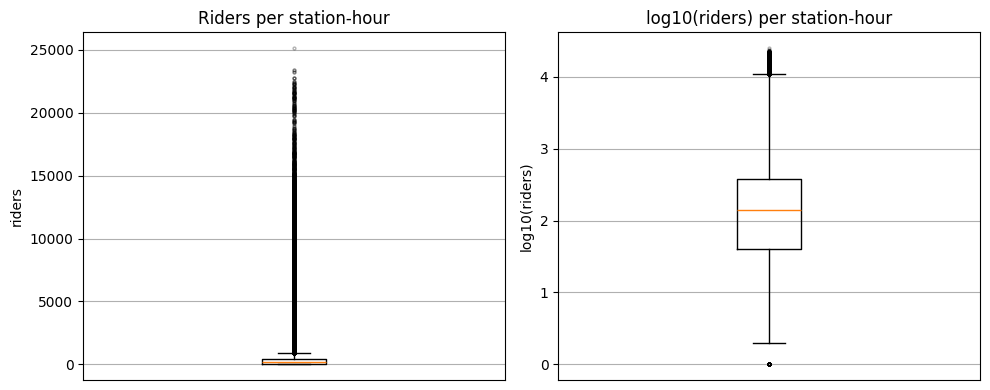

In [33]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 4))
ax1.boxplot(station_hour["ridership"], flierprops={"markersize": 2, "alpha": 0.3})
ax1.set(title="Riders per station-hour", ylabel="riders", xticks=[])
ax2.boxplot(np.log10(station_hour["ridership"]), flierprops={"markersize": 2, "alpha": 0.3})
ax2.set(title="log10(riders) per station-hour", ylabel="log10(riders)", xticks=[])
plt.tight_layout()
plt.show()

Asal *outlier* ekstrem menurut kompleks stasiun dan jam:

In [34]:
extreme = station_hour[station_hour["outlier"] == "extreme"]
top_extreme = extreme["station_complex"].value_counts().head(10)
print(f"Extreme outliers: {len(extreme):,} station-hours at {extreme['station_complex_id'].nunique()} station complexes")
print(f"Share held by the 10 complexes below: {top_extreme.sum() / len(extreme):.1%}")
top_extreme

Extreme outliers: 159,682 station-hours at 170 station complexes
Share held by the 10 complexes below: 31.2%


,count
station_complex,
"Times Sq-42 St/Port Authority Bus Terminal (1,2,3,7,A,C,E,N,Q,R,W,S)",6163
"Grand Central-42 St (4,5,6,7,S)",5291
"34 St-Herald Sq (B,D,F,M,N,Q,R,W)",5198
"34 St-Penn Station (A,C,E)",5130
"14 St-Union Sq (4,5,6,L,N,Q,R,W)",4962
"34 St-Penn Station (1,2,3)",4936
Flushing-Main St (7),4627
"Fulton St (2,3,4,5,A,C,J,Z)",4527
"59 St-Columbus Circle (1,A,C,B,D)",4506


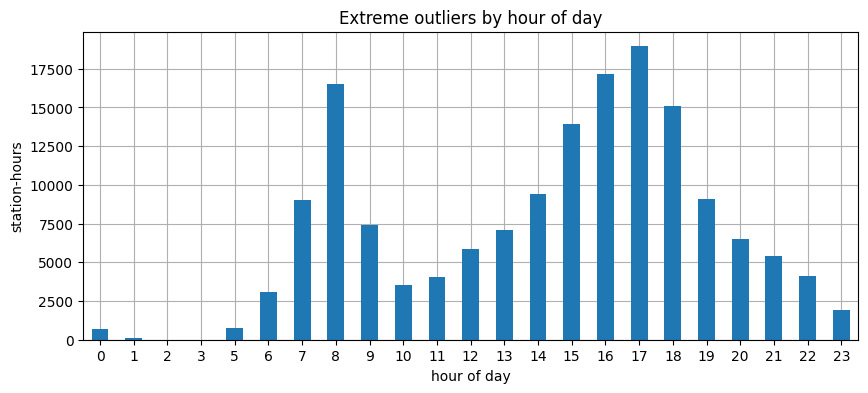

In [35]:
extreme_hours = extreme["transit_timestamp"].dt.hour.value_counts().sort_index()
extreme_hours.plot(kind="bar", rot=0, title="Extreme outliers by hour of day", xlabel="hour of day",
                   ylabel="station-hours")
plt.show()

In [36]:
(extreme_hours.sort_values(ascending=False) / len(extreme) * 100).head(6).rename_axis("hour").to_frame("share_pct")

,share_pct
hour,
17,11.86
16,10.74
8,10.36
18,9.44
15,8.71
14,5.89


**Temuan bagian 7.3:**

- Kedua batas bawah bernilai negatif, sedangkan jumlah penumpang paling sedikit 1, sehingga tidak ada *outlier* di sisi
  bawah.
- Sebanyak 137.783 jam-stasiun (4,32%) tergolong *outlier* ringan, yaitu di atas 885 penumpang, dan 159.682 (5,01%)
  tergolong *outlier* ekstrem, yaitu di atas 1.392 penumpang.
- *Outlier* ekstrem tersebar di 170 kompleks stasiun, tetapi 31,2% di antaranya berasal dari sepuluh kompleks seperti
  Times Sq-42 St dan Grand Central-42 St. Jam dengan *outlier* ekstrem terbanyak adalah 17.00 (11,86%), 16.00
  (10,74%), dan 08.00 (10,36%).
- *Outlier* ekstrem terkumpul pada stasiun terbesar dan jam ramai, dan barisnya lolos semua aturan validasi di bagian 5.
  Karena itu nilai tersebut diperlakukan sebagai data asli dan dipertahankan; kemencengannya ditangani dengan
  transformasi logaritma di bagian 8.

### 7.4 Bentuk sebaran

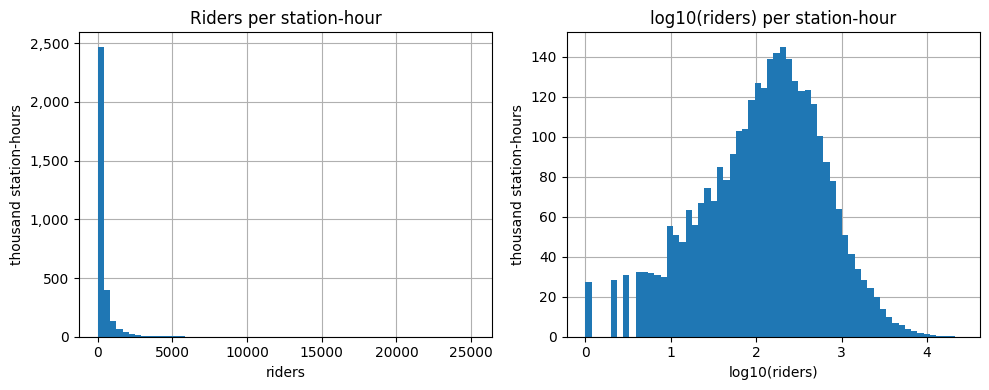

In [37]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 4))
station_hour["ridership"].plot(kind="hist", bins=60, ax=ax1, title="Riders per station-hour")
np.log10(station_hour["ridership"]).plot(kind="hist", bins=60, ax=ax2, title="log10(riders) per station-hour")
for ax, label in [(ax1, "riders"), (ax2, "log10(riders)")]:
    ax.set(xlabel=label, ylabel="thousand station-hours")
    ax.yaxis.set_major_formatter(lambda value, _: f"{value / 1000:,.0f}")
plt.tight_layout()
plt.show()

In [38]:
print(f"Skewness of riders per station-hour : {station_hour['ridership'].skew():.2f}")
print(f"Skewness after log1p transformation : {np.log1p(station_hour['ridership']).skew():.2f}")

Skewness of riders per station-hour : 7.67
Skewness after log1p transformation : -0.26


**Temuan bagian 7.4:**

- Histogram skala asli menumpuk di sisi kiri dengan ekor panjang ke kanan.
- Transformasi log(1 + x) menurunkan *skewness* dari 7,67 menjadi −0,26, dan histogram skala logaritma tampak mendekati
  simetris.

### 7.5 Pola waktu

Semua baris pada jam yang sama dijumlahkan menjadi total penumpang seluruh stasiun, tanpa baris bertanda
`is_dst_transition` (alasannya ada di bagian 6). Hari kerja berarti Senin sampai Jumat, termasuk hari libur yang jatuh
pada hari itu; akhir pekan berarti Sabtu dan Minggu.

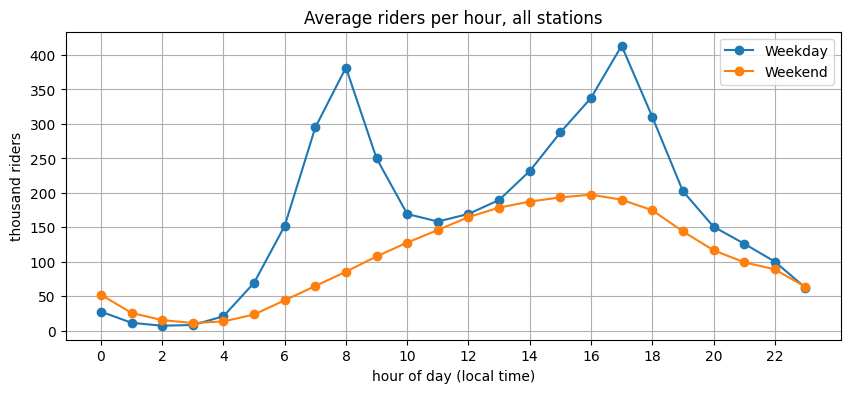

In [39]:
hourly = clean[~clean["is_dst_transition"]].groupby("transit_timestamp")["ridership"].sum().to_frame()
hourly["hour"] = hourly.index.hour
hourly["day_type"] = ["Weekend" if day >= 5 else "Weekday" for day in hourly.index.dayofweek]
hour_profile = hourly.groupby(["hour", "day_type"])["ridership"].mean().unstack() / 1000
ax = hour_profile.plot(marker="o", xticks=range(0, 24, 2), title="Average riders per hour, all stations",
                       xlabel="hour of day (local time)", ylabel="thousand riders")
ax.legend(title="")
plt.show()

In [40]:
hour_profile

day_type,Weekday,Weekend
hour,,
0,27.65,52.17
1,11.39,25.73
2,7.15,15.33
3,8.20,11.06
4,20.83,13.35
5,69.37,23.46
6,151.97,44.04
7,294.84,64.72
8,381.79,85.57


Total harian memakai semua baris, termasuk yang bertanda `is_dst_transition`, karena tanggal baris-baris itu tetap
benar.

In [41]:
daily = clean.groupby(clean["transit_timestamp"].dt.normalize())["ridership"].sum()
daily.index.name = "date"
DAY_ORDER = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
by_weekday = daily.groupby(daily.index.day_name()).agg(days="count", average_riders="mean")
by_weekday = by_weekday.reindex(DAY_ORDER).rename_axis("day")
by_weekday

,days,average_riders
day,,
Monday,45,"3,670,857.53"
Tuesday,45,"4,303,968.42"
Wednesday,45,"4,379,145.16"
Thursday,45,"4,314,271.13"
Friday,45,"3,994,616.42"
Saturday,45,"2,833,906.91"
Sunday,45,"2,199,471.98"


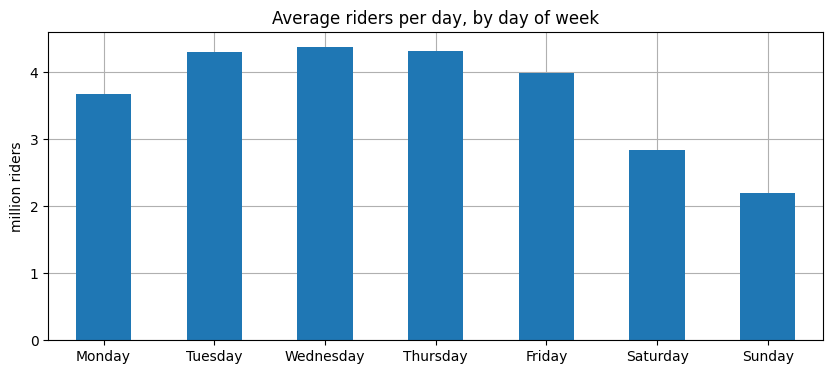

In [42]:
(by_weekday["average_riders"] / 1e6).plot(kind="bar", rot=0, title="Average riders per day, by day of week",
                                         xlabel="", ylabel="million riders")
plt.show()

In [43]:
monthly = daily.groupby(daily.index.to_period("M")).agg(days="count", average_riders="mean").rename_axis("month")
monthly

,days,average_riders
month,,
2026-01,31,"3,287,017.94"
2026-02,28,"3,451,360.79"
2026-03,31,"3,754,660.65"
2026-04,30,"3,801,507.03"
2026-05,31,"3,724,153.42"
2026-06,30,"3,859,547.03"
2026-07,31,"3,557,978.84"
2026-08,31,"3,419,452.74"
2026-09,30,"3,757,015.10"


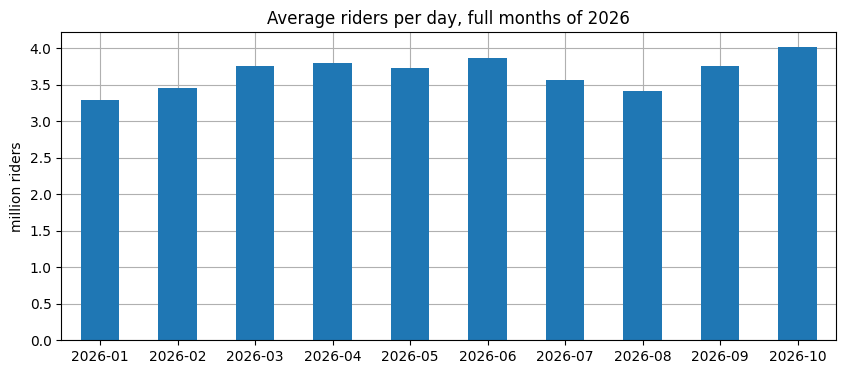

In [44]:
full_months = monthly[monthly["days"] == monthly.index.days_in_month]
(full_months["average_riders"] / 1e6).plot(kind="bar", rot=0, title="Average riders per day, full months of 2026",
                                           xlabel="", ylabel="million riders")
plt.show()

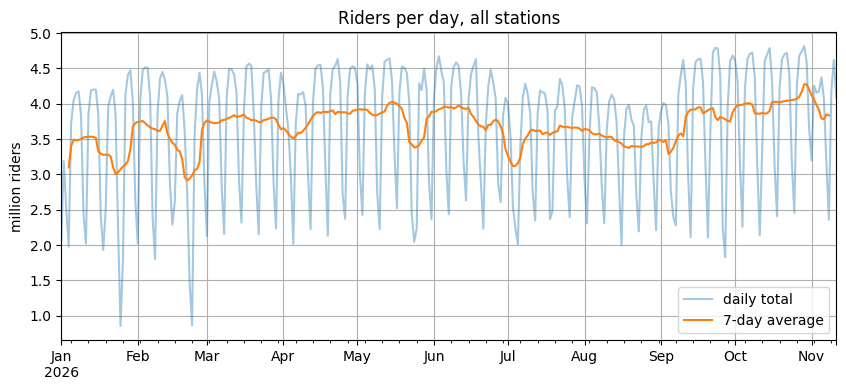

In [45]:
ax = (daily / 1e6).plot(alpha=0.4, label="daily total", title="Riders per day, all stations", ylabel="million riders")
(daily.rolling(7, center=True).mean() / 1e6).plot(ax=ax, label="7-day average", xlabel="")
ax.legend()
plt.show()

Lima hari dengan penumpang paling sedikit di seluruh periode:

In [46]:
lowest_days = daily.nsmallest(5).to_frame("riders")
lowest_days["day"] = lowest_days.index.day_name()
lowest_days["riders"] = lowest_days["riders"].map("{:,}".format)
lowest_days

,riders,day
date,,
2026-01-25,"850,416",Sunday
2026-02-23,"861,364",Monday
2026-02-22,"1,470,158",Sunday
2026-02-08,"1,800,419",Sunday
2026-01-26,"1,803,654",Monday


Sepuluh hari Senin sampai Jumat dengan penumpang paling sedikit:

In [47]:
weekdays = daily[daily.index.dayofweek < 5]
lowest_weekdays = weekdays.nsmallest(10).to_frame("riders")
lowest_weekdays["day"] = lowest_weekdays.index.day_name()
lowest_weekdays["riders"] = lowest_weekdays["riders"].map("{:,}".format)
lowest_weekdays

,riders,day
date,,
2026-02-23,"861,364",Monday
2026-01-26,"1,803,654",Monday
2026-01-01,"2,057,867",Thursday
2026-05-25,"2,233,053",Monday
2026-09-07,"2,272,439",Monday
2026-01-19,"2,501,951",Monday
2026-07-03,"2,542,337",Friday
2026-02-16,"2,607,977",Monday
2026-01-02,"3,186,729",Friday


**Temuan bagian 7.5:**

- Pada hari kerja, rata-rata penumpang memuncak pukul 17.00 (413,52 ribu) dan pukul 08.00 (381,79 ribu); di antara
  keduanya, jam tersepi adalah pukul 11.00 (158,36 ribu).
- Akhir pekan tidak memiliki puncak pagi. Jumlah penumpang bertambah perlahan dan tertinggi pukul 16.00 (197,38 ribu),
  dengan pukul 14.00–17.00 berada pada kisaran 187–197 ribu.
- Jam tersepi adalah pukul 02.00 pada hari kerja (7,15 ribu) dan pukul 03.00 pada akhir pekan (11,06 ribu). Pukul
  00.00 hari Sabtu dan Minggu, yaitu tepat setelah Jumat malam dan Sabtu malam, lebih ramai (52,17 ribu) daripada
  pukul 00.00 hari kerja (27,65 ribu).
- Setiap hari dalam seminggu muncul tepat 45 kali. Selasa, Rabu, dan Kamis memiliki rata-rata yang hampir sama
  (4,30–4,38 juta per hari) dan paling tinggi; Jumat 3,99 juta, Senin 3,67 juta, Sabtu 2,83 juta, dan Minggu 2,20 juta.
- Di antara sepuluh bulan lengkap, rata-rata harian terendah terjadi pada Januari (3,29 juta) dan tertinggi pada
  Oktober (4,02 juta). Agustus (3,42 juta) lebih rendah daripada Juli dan September.
- Hari tersepi adalah Minggu, 25 Januari 2026 (850.416 penumpang), disusul Senin, 23 Februari (861.364). Keduanya
  berdampingan dengan hari yang juga sepi, yaitu Senin, 26 Januari dan Minggu, 22 Februari. Data tidak memuat
  keterangan penyebabnya.
- Tujuh dari sepuluh hari Senin–Jumat tersepi bertepatan dengan hari libur federal menurut
  [kalender OPM](https://www.opm.gov/policy-data-oversight/pay-leave/federal-holidays/): 1 Januari, 19 Januari, 16 Februari, 25 Mei, 3 Juli, 7 September, dan 12 Oktober 2026.
  Tiga sisanya (23 Februari, 26 Januari, dan 2 Januari) bukan hari libur federal.

### 7.6 *Borough* dan kompleks stasiun

In [48]:
boroughs = station_hour.groupby("borough").agg(stations=("station_complex_id", "nunique"), riders=("ridership", "sum"))
boroughs["riders_million"] = boroughs["riders"] / 1e6
boroughs["share_pct"] = boroughs["riders"] / boroughs["riders"].sum() * 100
boroughs["per_station_per_day"] = boroughs["riders"] / boroughs["stations"] / len(daily)
boroughs.drop(columns="riders").sort_values("riders_million", ascending=False)

,stations,riders_million,share_pct,per_station_per_day
borough,,,,
Manhattan,123,649.05,56.13,"16,751.83"
Brooklyn,156,258.97,22.40,"5,270.04"
Queens,79,168.95,14.61,"6,789.05"
Bronx,68,77.39,6.69,"3,613.15"
Staten Island,2,1.97,0.17,"3,130.34"


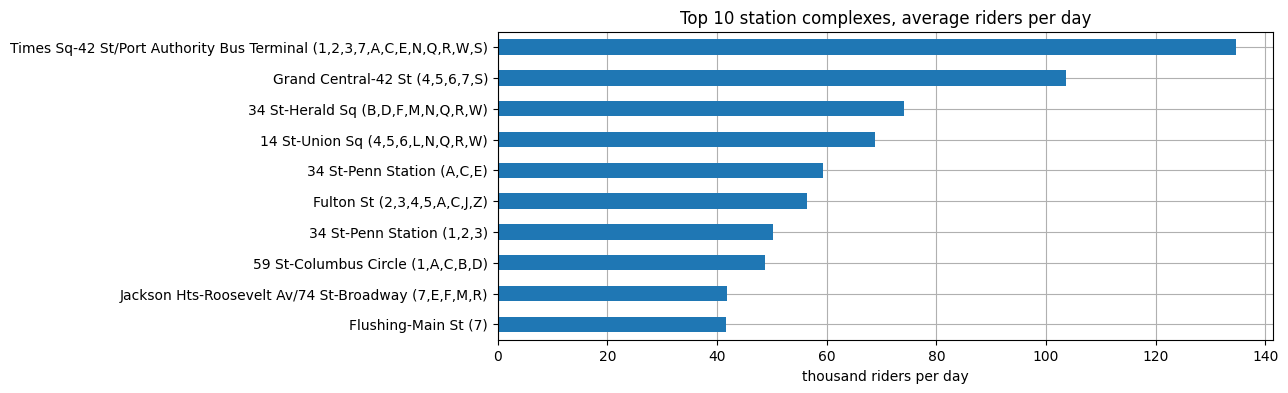

In [49]:
per_station = station_hour.groupby(["station_complex", "borough"])["ridership"].sum() / len(daily)
per_station = per_station.sort_values(ascending=False)
top10 = per_station.head(10).droplevel("borough") / 1000
ax = top10.sort_values().plot(kind="barh", title="Top 10 station complexes, average riders per day")
ax.set_xlabel("thousand riders per day")
ax.set_ylabel("")
plt.show()

In [50]:
per_station.head(10).to_frame("riders_per_day")

,,riders_per_day
station_complex,borough,
"Times Sq-42 St/Port Authority Bus Terminal (1,2,3,7,A,C,E,N,Q,R,W,S)",Manhattan,"134,606.47"
"Grand Central-42 St (4,5,6,7,S)",Manhattan,"103,660.00"
"34 St-Herald Sq (B,D,F,M,N,Q,R,W)",Manhattan,"74,033.95"
"14 St-Union Sq (4,5,6,L,N,Q,R,W)",Manhattan,"68,786.12"
"34 St-Penn Station (A,C,E)",Manhattan,"59,356.58"
"Fulton St (2,3,4,5,A,C,J,Z)",Manhattan,"56,320.09"
"34 St-Penn Station (1,2,3)",Manhattan,"50,204.71"
"59 St-Columbus Circle (1,A,C,B,D)",Manhattan,"48,749.29"
"Jackson Hts-Roosevelt Av/74 St-Broadway (7,E,F,M,R)",Queens,"41,800.50"


In [51]:
print(f"Top 10 complexes : {per_station.head(10).sum() / per_station.sum():.1%} of all riders")
print(f"Top 50 complexes : {per_station.head(50).sum() / per_station.sum():.1%} of all riders")

Top 10 complexes : 18.5% of all riders
Top 50 complexes : 45.4% of all riders


**Temuan bagian 7.6:**

- Di data ini, Manhattan memiliki 123 dari 428 kompleks stasiun tetapi menyumbang 56,13% penumpang. Satu kompleks di
  Manhattan rata-rata dimasuki 16.752 penumpang per hari, sekitar 4,6 kali kompleks di Bronx (3.613).
- Brooklyn memiliki kompleks terbanyak (156) dengan porsi 22,40%, sedangkan data hanya memuat 2 kompleks di Staten
  Island dengan porsi 0,17%.
- Times Sq-42 St (134.606 penumpang per hari) dan Grand Central-42 St (103.660) jauh di atas kompleks lain. Delapan dari
  sepuluh kompleks teratas berada di Manhattan dan dua di Queens. 34 St-Penn Station tercatat sebagai dua kompleks
  terpisah, yaitu jalur A, C, E dan jalur 1, 2, 3.
- Sepuluh kompleks teratas menyumbang 18,5% penumpang, dan 50 kompleks teratas 45,4%.

### 7.7 Cara bayar

Porsi dihitung dari jumlah penumpang (`ridership`), bukan dari jumlah baris.

In [52]:
month = clean["transit_timestamp"].dt.to_period("M")
payment = clean.groupby([month, "payment_method"])["ridership"].sum().unstack() / 1e6
payment["omny_pct"] = payment["omny"] / (payment["omny"] + payment["metrocard"]) * 100
payment.rename(columns={"omny": "omny_million", "metrocard": "metrocard_million"}).rename_axis("month")

payment_method,metrocard_million,omny_million,omny_pct
month,,,
2026-01,2.74,99.16,97.31
2026-02,2.12,94.52,97.81
2026-03,1.92,114.47,98.35
2026-04,1.38,112.67,98.79
2026-05,1.15,114.30,99.00
2026-06,0.96,114.82,99.17
2026-07,0.90,109.40,99.18
2026-08,0.70,105.30,99.34
2026-09,0.47,112.24,99.58


In [53]:
by_fare = clean.groupby("fare_class_category")["ridership"].sum().sort_values(ascending=False)
(by_fare / by_fare.sum() * 100).to_frame("share_pct")

,share_pct
fare_class_category,
OMNY - Full Fare,81.29
OMNY - Students,5.88
OMNY - Seniors & Disability,5.61
OMNY - Fair Fare,4.02
OMNY - Other,2.09
Metrocard - Other,0.85
Metrocard - Unlimited 30-Day,0.13
Metrocard - Full Fare,0.06
Metrocard - Unlimited 7-Day,0.04


**Temuan bagian 7.7:**

- OMNY sudah dominan sejak awal tahun: porsinya 97,31% pada Januari dan naik setiap bulan sampai 99,76% pada November
  (dihitung dari 1–11 November).
- `OMNY - Full Fare` mencakup 81,29% penumpang, sedangkan setiap jenis tarif MetroCard berada di bawah 1%.

### 7.8 Korelasi

Korelasi dihitung pada tabel `station_hour` untuk tujuh variabel numerik: penumpang, transfer, jam, hari dalam
seminggu (Senin = 0), bulan, serta koordinat stasiun. Koefisien Pearson mengukur hubungan linear, sedangkan Spearman
mengukur hubungan monoton berdasarkan peringkat; keduanya bernilai −1 sampai 1.

In [54]:
variables = station_hour[["ridership", "transfers", "latitude", "longitude"]].copy()
variables["hour"] = station_hour["transit_timestamp"].dt.hour
variables["day_of_week"] = station_hour["transit_timestamp"].dt.dayofweek
variables["month"] = station_hour["transit_timestamp"].dt.month
pearson = variables.corr()
spearman = variables.corr(method="spearman")

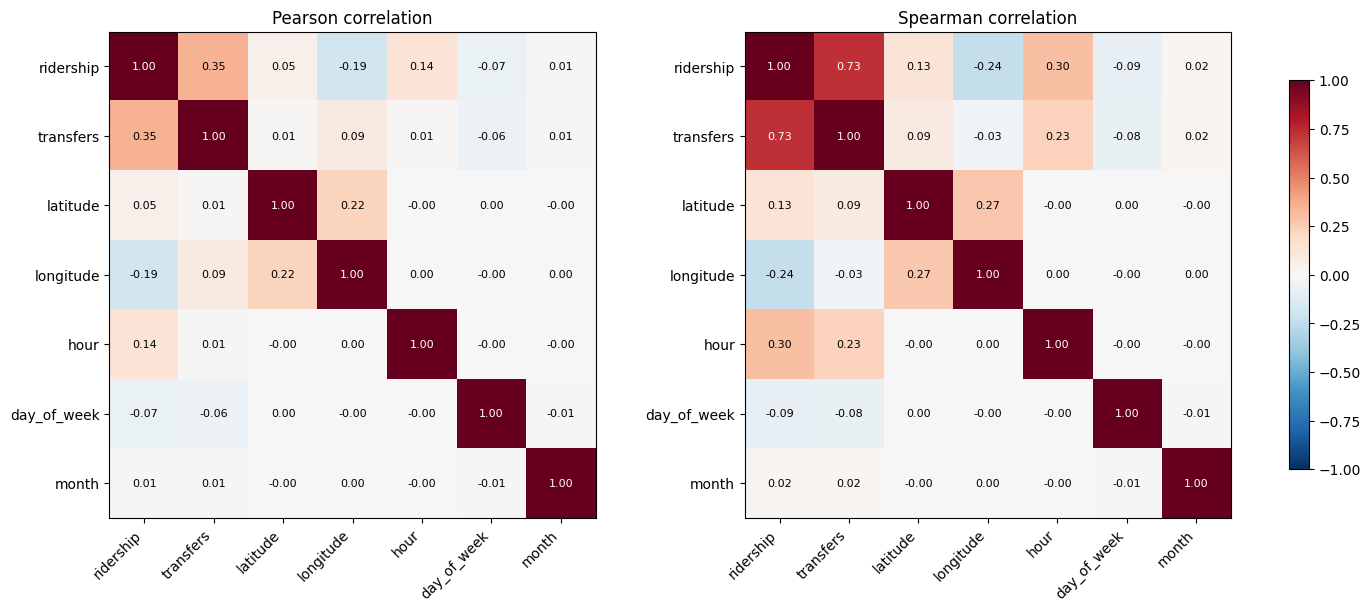

In [55]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6), layout="constrained")
for ax, (name, matrix) in zip(axes, [("Pearson", pearson), ("Spearman", spearman)]):
    image = ax.imshow(matrix, vmin=-1, vmax=1, cmap="RdBu_r")
    ax.set(title=f"{name} correlation", xticks=range(len(matrix)), yticks=range(len(matrix)))
    ax.set_xticklabels(matrix.columns, rotation=45, ha="right")
    ax.set_yticklabels(matrix.index)
    ax.grid(False)
    for i in range(len(matrix)):
        for j in range(len(matrix)):
            value = matrix.iloc[i, j]
            ax.text(j, i, f"{value:.2f}", ha="center", va="center", fontsize=8,
                    color="white" if abs(value) > 0.6 else "black")
fig.colorbar(image, ax=axes, shrink=0.8)
plt.show()

In [56]:
pd.DataFrame({"pearson": pearson["ridership"], "spearman": spearman["ridership"]}).drop("ridership")

,pearson,spearman
transfers,0.35,0.73
latitude,0.05,0.13
longitude,-0.19,-0.24
hour,0.14,0.30
day_of_week,-0.07,-0.09
month,0.01,0.02


Hubungan `ridership` dan `transfers` dalam diagram pencar. Agar titiknya terbaca, yang digambar adalah 20.000
baris acak (`random_state=0`); koefisien di atas tetap dihitung dari semua baris.

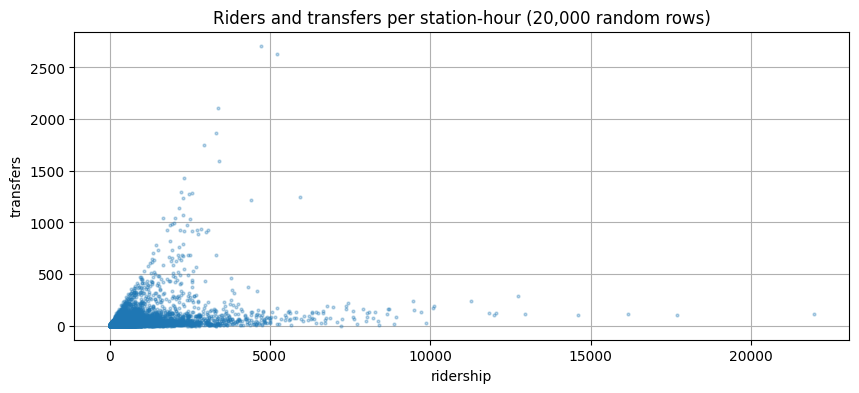

In [57]:
sample = station_hour.sample(20_000, random_state=0)
sample.plot(kind="scatter", x="ridership", y="transfers", s=4, alpha=0.3,
            title="Riders and transfers per station-hour (20,000 random rows)")
plt.show()

**Temuan bagian 7.8:**

- Korelasi terkuat dengan `ridership` adalah `transfers`: 0,35 menurut Pearson dan 0,73 menurut Spearman. Selisih
  sebesar ini sejalan dengan banyaknya nilai ekstrem (bagian 7.3), yang lebih memengaruhi Pearson daripada Spearman.
- Diagram pencar memperlihatkan jumlah transfer umumnya ikut naik bersama jumlah penumpang, dengan sebaran yang lebar.
- `hour` berkorelasi lemah dengan `ridership` (Pearson 0,14; Spearman 0,30) walaupun pola jamnya sangat jelas di bagian
  7.5. Hubungan jam dan penumpang memiliki dua puncak, bukan naik atau turun searah, sehingga tidak tertangkap oleh
  koefisien korelasi.
- Variabel lainnya hanya berkorelasi sangat lemah dengan `ridership` (|r| ≤ 0,24): `longitude` −0,19/−0,24,
  `day_of_week` −0,07/−0,09, `latitude` 0,05/0,13, dan `month` 0,01/0,02.

## 8. Persiapan Data untuk Pemodelan

Tabel `station_hour` disiapkan menjadi *dataset* pemodelan dengan satu baris per kompleks stasiun per jam. Langkahnya:

1. Fitur waktu `hour`, `day_of_week`, `is_weekend`, dan `month` diturunkan dari `transit_timestamp`, karena bagian 7.5
   menunjukkan jumlah penumpang berubah menurut jam, hari, dan bulan.
2. Penanda `is_dst_transition` diikutkan agar jam yang labelnya tidak pasti dapat dikecualikan.
3. Kolom `log_ridership = log(1 + ridership)` ditambahkan sebagai target yang sebarannya hampir simetris (bagian 7.4).
4. `borough` diubah menjadi kolom biner (*one-hot encoding*) karena model numerik tidak dapat membaca teks.

Kolom `transfers` tidak diikutkan karena merupakan bagian dari `ridership`; memakainya sebagai fitur berarti
memasukkan sebagian nilai target ke dalam masukan model. *Outlier* dipertahankan (bagian 7.3), dan normalisasi skala
belum diterapkan karena kebutuhannya bergantung pada model yang dipilih.

In [58]:
prepared = station_hour[["transit_timestamp", "station_complex_id", "borough", "ridership"]].copy()
prepared["hour"] = prepared["transit_timestamp"].dt.hour
prepared["day_of_week"] = prepared["transit_timestamp"].dt.dayofweek
prepared["is_weekend"] = (prepared["day_of_week"] >= 5).astype("int8")
prepared["month"] = prepared["transit_timestamp"].dt.month
prepared["is_dst_transition"] = prepared["transit_timestamp"].isin(DST_HOURS).astype("int8")
prepared["log_ridership"] = np.log1p(prepared["ridership"])
prepared = pd.get_dummies(prepared, columns=["borough"], prefix="borough", dtype="int8")
prepared.head()

,transit_timestamp,station_complex_id,ridership,hour,day_of_week,is_weekend,month,is_dst_transition,log_ridership,borough_Bronx,borough_Brooklyn,borough_Manhattan,borough_Queens,borough_Staten Island
0,2026-01-01,1,134,0,3,0,1,0,4.91,0,0,0,1,0
1,2026-01-01,10,398,0,3,0,1,0,5.99,0,0,1,0,0
2,2026-01-01,100,60,0,3,0,1,0,4.11,0,1,0,0,0
3,2026-01-01,101,231,0,3,0,1,0,5.45,0,1,0,0,0
4,2026-01-01,103,134,0,3,0,1,0,4.91,0,0,1,0,0


In [59]:
print(f"Rows: {len(prepared):,} | columns: {prepared.shape[1]} | missing values: {prepared.isna().sum().sum()}")
prepared.dtypes

Rows: 3,187,977 | columns: 14 | missing values: 0


,0
transit_timestamp,datetime64[ns]
station_complex_id,object
ridership,int32
hour,int32
day_of_week,int32
is_weekend,int8
month,int32
is_dst_transition,int8
log_ridership,float64
borough_Bronx,int8


In [60]:
prepared.to_parquet("mta_subway_station_hour_2026.parquet", index=False)
print(f"Saved mta_subway_station_hour_2026.parquet ({len(prepared):,} rows)")

Saved mta_subway_station_hour_2026.parquet (3,187,977 rows)


## 9. Kesimpulan

1. **Kelengkapan data.** Data 2026 yang diunduh, 17.584.367 baris dari 1 Januari sampai 11 November 2026, sama
   persis dengan ringkasan server MTA pada seluruh 315 hari.
2. **Kualitas dan penanganannya.** Masalah yang ditemukan adalah 294 nilai `transfers` negatif, 3 baris St George
   dengan moda keliru, kolom koordinat yang terduplikasi, tipe desimal untuk hitungan, dan label jam DST. Semuanya
   ditangani tanpa menghapus baris, dan validasi ulang tidak menemukan pelanggaran.
3. **Sebaran dan *outlier*.** Penumpang per stasiun per jam memiliki Q1 40, median 140, dan Q3 378, dengan *skewness*
   7,67. Sekitar 9,3% jam-stasiun berada di atas batas IQR; nilai itu berasal dari stasiun besar pada jam ramai
   sehingga dipertahankan, sedangkan transformasi logaritma menurunkan *skewness* menjadi −0,26.
4. **Waktu dan lokasi teramai.** Hari kerja memuncak pukul 08.00 dan 17.00, akhir pekan pukul 16.00; Selasa sampai
   Kamis adalah hari teramai dan Oktober bulan teramai. Manhattan menyumbang 56,13% penumpang, dengan Times Sq-42 St
   sebagai kompleks tersibuk.
5. **Korelasi.** Hanya `transfers` yang berkorelasi cukup kuat dengan `ridership` (Spearman 0,73), sedangkan pola jam
   yang jelas tidak tercermin pada koefisien korelasi karena bentuknya tidak searah.

Hasil akhirnya adalah *dataset* stasiun-jam berisi 3.187.977 baris dan 14 kolom tanpa nilai kosong, yang siap dipakai
pada tahap pemodelan.